# Our Original CNN Model

This Jupyter Notebook contains our original `convolutional neural network (CNN)` model used for image recognition. The model is trained to recognize four different types of dinnerware items from images. The model is created using the `Keras` library with `TesnsorFlow` as the backend. 

`Matplotlib.pyplot` and `NumPy` libraries are used for formatting and visualising data and performance results. `Time` library provides a method for measuring the model's training time. The `Scikit Learn` library is used to calculate performance metrics and also to display them more visually.

In [1]:
import os, shutil, pathlib
os.environ["KERAS_BACKEND"] = "tensorflow"

import keras
from keras import layers
from keras.utils import image_dataset_from_directory
import tensorflow as tf

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay, classification_report
import time

keras.utils.set_random_seed(2)

C:\Users\riikk\anaconda3\envs\keras\Lib\site-packages\requests\__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


Using the `keras.utils.set_random_seed` function reduces the difference between different runs so that performance results are more similar if the model is created and trained again. 

In [2]:
'''
remove later? -> add as file to utils

categories = ["bowl", "glass", "mug", "plate"]
splits = ["train", "validation", "test"]
image_extensions = ('.jpg', '.jpeg')

def count_dataset_images():
    for split in splits:
        print(f"\nsplit: {split}")
        total = 0

        for category in categories:
            folder = base_dir / split / category

            image_count = sum(
                1 for filename in os.listdir(folder)
                if filename.lower().endswith(image_extensions)
            )

            total += image_count

            print(f"  {category}: {image_count} images")

        print(f"  Total: {total} images")


count_dataset_images()

'''

'\nremove later? -> add as file to utils\n\ncategories = ["bowl", "glass", "mug", "plate"]\nsplits = ["train", "validation", "test"]\nimage_extensions = (\'.jpg\', \'.jpeg\')\n\ndef count_dataset_images():\n    for split in splits:\n        print(f"\nsplit: {split}")\n        total = 0\n\n        for category in categories:\n            folder = base_dir / split / category\n\n            image_count = sum(\n                1 for filename in os.listdir(folder)\n                if filename.lower().endswith(image_extensions)\n            )\n\n            total += image_count\n\n            print(f"  {category}: {image_count} images")\n\n        print(f"  Total: {total} images")\n\n\ncount_dataset_images()\n\n'

## Data Preprocessing

The dataset used for the training contains images of four different types of dinnerware items: bowls, drinking glasses, mugs and plates. The images were preprocessed using Python wiht function from the `Pillow (PIL)` library. The images were cropped, resized, converted to RGB and renamed with code. For a more detailed description of the dataset refer to the `Assignment2_raport.ipynb` notebook.

The dataset is fetched from the base folder using the `pathlib.Path` class and Keras library's `image_dataset_from_directory` function. For the function to work correctly the dinnerware images need to be divided in their own folders with aproriate class names. The function is used three times to get subsets for training, validation and testing. The `batch_size` is 32 and `image_size` is 224x224 pixels. The `seed` parameter ensures that the initial shuffle of the datasets is always the same increasing reproducbility.

In [3]:
base_dir = pathlib.Path("./datasets/dinnerware_mix_background")

image_size = (224, 224)
batch_size = 32
seed = 123

train_dataset = image_dataset_from_directory(
    base_dir / "train",
    image_size = image_size,
    batch_size = batch_size,
    seed = seed,
)
validation_dataset = image_dataset_from_directory(
    base_dir / "validation",
    image_size = image_size,
    batch_size = batch_size,
    shuffle=False,
    seed = seed,
)
test_dataset = image_dataset_from_directory(
    base_dir / "test",
    image_size = image_size,
    batch_size = batch_size,
    shuffle=False,
    seed = seed,
)

for data_batch, labels_batch in train_dataset:
    print("Data batch shape:", data_batch.shape)
    print("Labels batch shape:", labels_batch.shape)
    break

Found 296 files belonging to 4 classes.
Found 93 files belonging to 4 classes.
Found 95 files belonging to 4 classes.
Data batch shape: (32, 224, 224, 3)
Labels batch shape: (32,)


The training set has 296 images, the validation set has 93 images and the test set has 95 images. A batch has 32 images wiht 224 x 224 dimension and they are RGB colour images that contain three colour channels. This explains the batch shape: (32, 224, 224, 3).

Below are some examples of the images in the training dataset with their labels or class names.

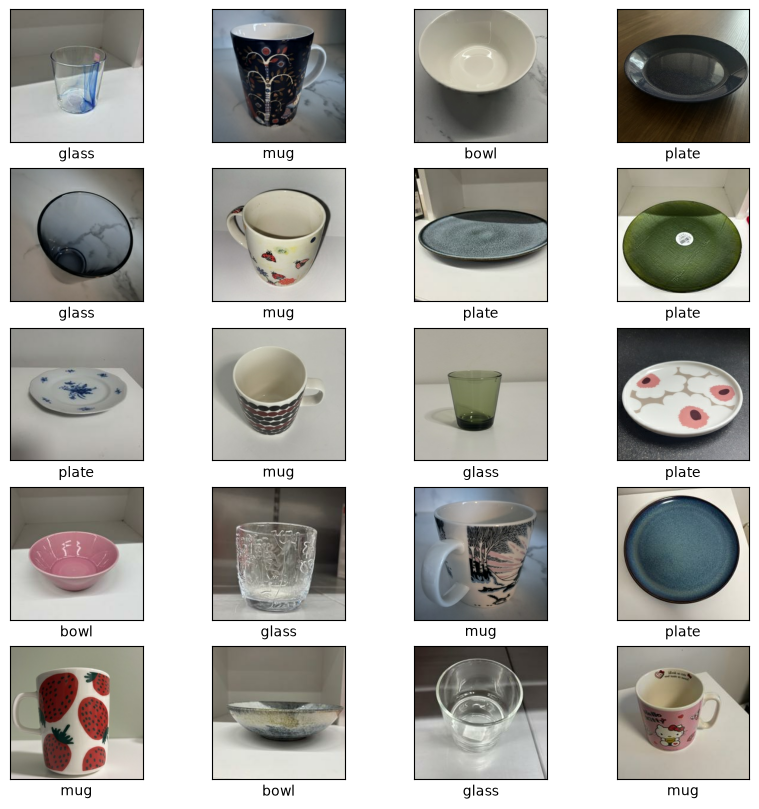

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))

class_names = train_dataset.class_names

for images, labels in train_dataset.take(1):
    for i in range(20):
        plt.subplot(5, 4, i + 1)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)

        plt.imshow(images[i].numpy().astype("uint8"))
        plt.xlabel(class_names[labels[i]])

plt.show()

## Modelling

In [5]:
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),
        layers.RandomContrast(0.1)
    ]
)

model = keras.Sequential([
    keras.Input(shape=(224, 224, 3)),
    data_augmentation,
    layers.Rescaling(1.0/255),

    layers.BatchNormalization(),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   

    layers.Conv2D(128, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   
    
    layers.Flatten(),
    layers.Dropout(0.3),
    layers.Dense(len(class_names), activation="softmax"),
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 3)    │            12 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 220, 220, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 110, 110, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 108, 108, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 52, 52, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 24, 24, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 10, 10, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 5, 5, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 3200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │        12,804 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 161,488 (630.81 KB)

 Trainable params: 161,482 (630.79 KB)

 Non-trainable params: 6 (24.00 B)

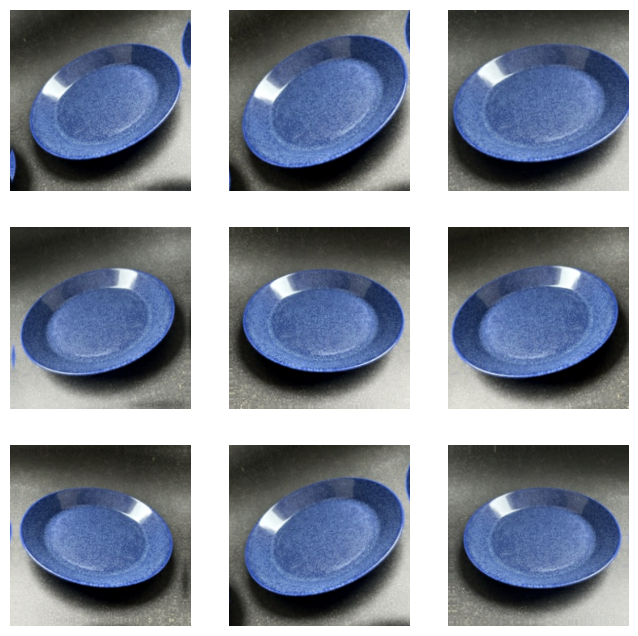

In [6]:
for images, labels in train_dataset.take(1):
    img = images[0:1]

plt.figure(figsize=(8, 8))
for i in range(9):
    aug = data_augmentation(img, training=True)
    plt.subplot(3, 3, i + 1)
    plt.imshow(keras.ops.convert_to_numpy(aug[0]).astype("uint8"))
    plt.axis("off")
plt.show()

## Compile and train the model

In [7]:
model.compile(
    loss=keras.losses.SparseCategoricalCrossentropy(),
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    metrics=["accuracy"],
)

In [8]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="convnet_from_scratch_with_augmentation.keras",
        save_best_only=True,
        monitor="val_loss"),
    keras.callbacks.EarlyStopping(
        monitor="val_loss", 
        patience=7, 
        restore_best_weights=True)
]

t0 = time.time()

history = model.fit(
    train_dataset, 
    batch_size=128,
    epochs=70, 
    validation_data=validation_dataset, 
    callbacks=callbacks
)

train_time = time.time() - t0
print(f"Training time: {train_time:.1f} s")

Epoch 1/70


/opt/anaconda3/envs/keras/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


10/10 ━━━━━━━━━━━━━━━━━━━━ 6s 514ms/step - accuracy: 0.2568 - loss: 1.3915 - val_accuracy: 0.1720 - val_loss: 1.3892
Epoch 2/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 519ms/step - accuracy: 0.3243 - loss: 1.3714 - val_accuracy: 0.2473 - val_loss: 1.3879
Epoch 3/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 528ms/step - accuracy: 0.3311 - loss: 1.3637 - val_accuracy: 0.2688 - val_loss: 1.3861
Epoch 4/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 536ms/step - accuracy: 0.3784 - loss: 1.3480 - val_accuracy: 0.2796 - val_loss: 1.3837
Epoch 5/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 540ms/step - accuracy: 0.4426 - loss: 1.3188 - val_accuracy: 0.2688 - val_loss: 1.3786
Epoch 6/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 544ms/step - accuracy: 0.4257 - loss: 1.2961 - val_accuracy: 0.2581 - val_loss: 1.3739
Epoch 7/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 548ms/step - accuracy: 0.4527 - loss: 1.2444 - val_accuracy: 0.3763 - val_loss: 1.3658
Epoch 8/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 6s 553ms/step - accuracy: 0.4696 - loss: 1.2214 - val_accuracy: 0.3978 - val_

## Learning Curves

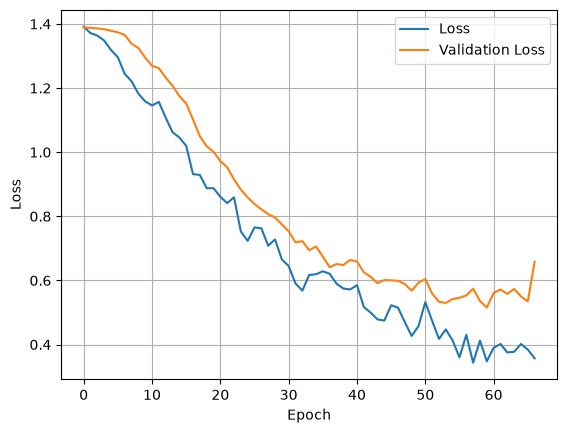

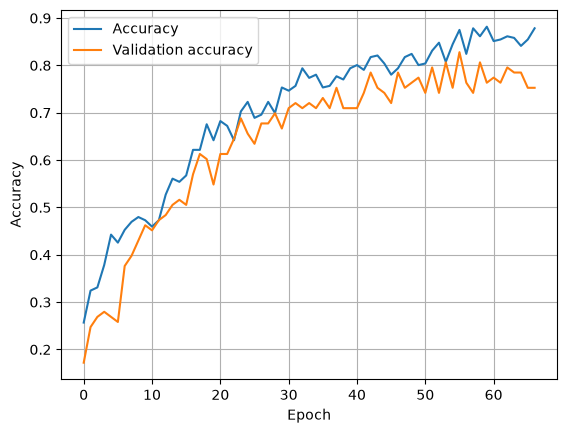

In [9]:
plt.plot(history.history["loss"], label="Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid()
plt.show()

plt.plot(history.history["accuracy"], label="Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.grid()
plt.show()

## Test perfomance

In [10]:
test_model = keras.models.load_model("convnet_from_scratch_with_augmentation.keras")
test_loss, test_acc = test_model.evaluate(test_dataset)

print(f"Test accuracy: {test_acc:.3f}")
print(f"Test loss: {test_loss:.3f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 154ms/step - accuracy: 0.7263 - loss: 0.6105
Test accuracy: 0.726
Test loss: 0.610


In [11]:
y_true = np.concatenate([y for x, y in test_dataset], axis=0)

probs = test_model.predict(test_dataset)
y_pred = np.argmax(probs, axis=1)

print(classification_report(y_true, y_pred, target_names=class_names))

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 199ms/step
              precision    recall  f1-score   support

        bowl       0.64      0.69      0.67        26
       glass       0.79      0.79      0.79        24
         mug       0.79      0.71      0.75        21
       plate       0.71      0.71      0.71        24

    accuracy                           0.73        95
   macro avg       0.73      0.73      0.73        95
weighted avg       0.73      0.73      0.73        95



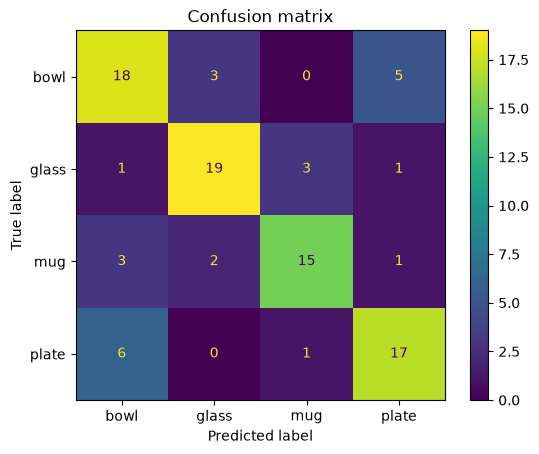

In [12]:
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot()
plt.title("Confusion matrix")
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 196ms/step


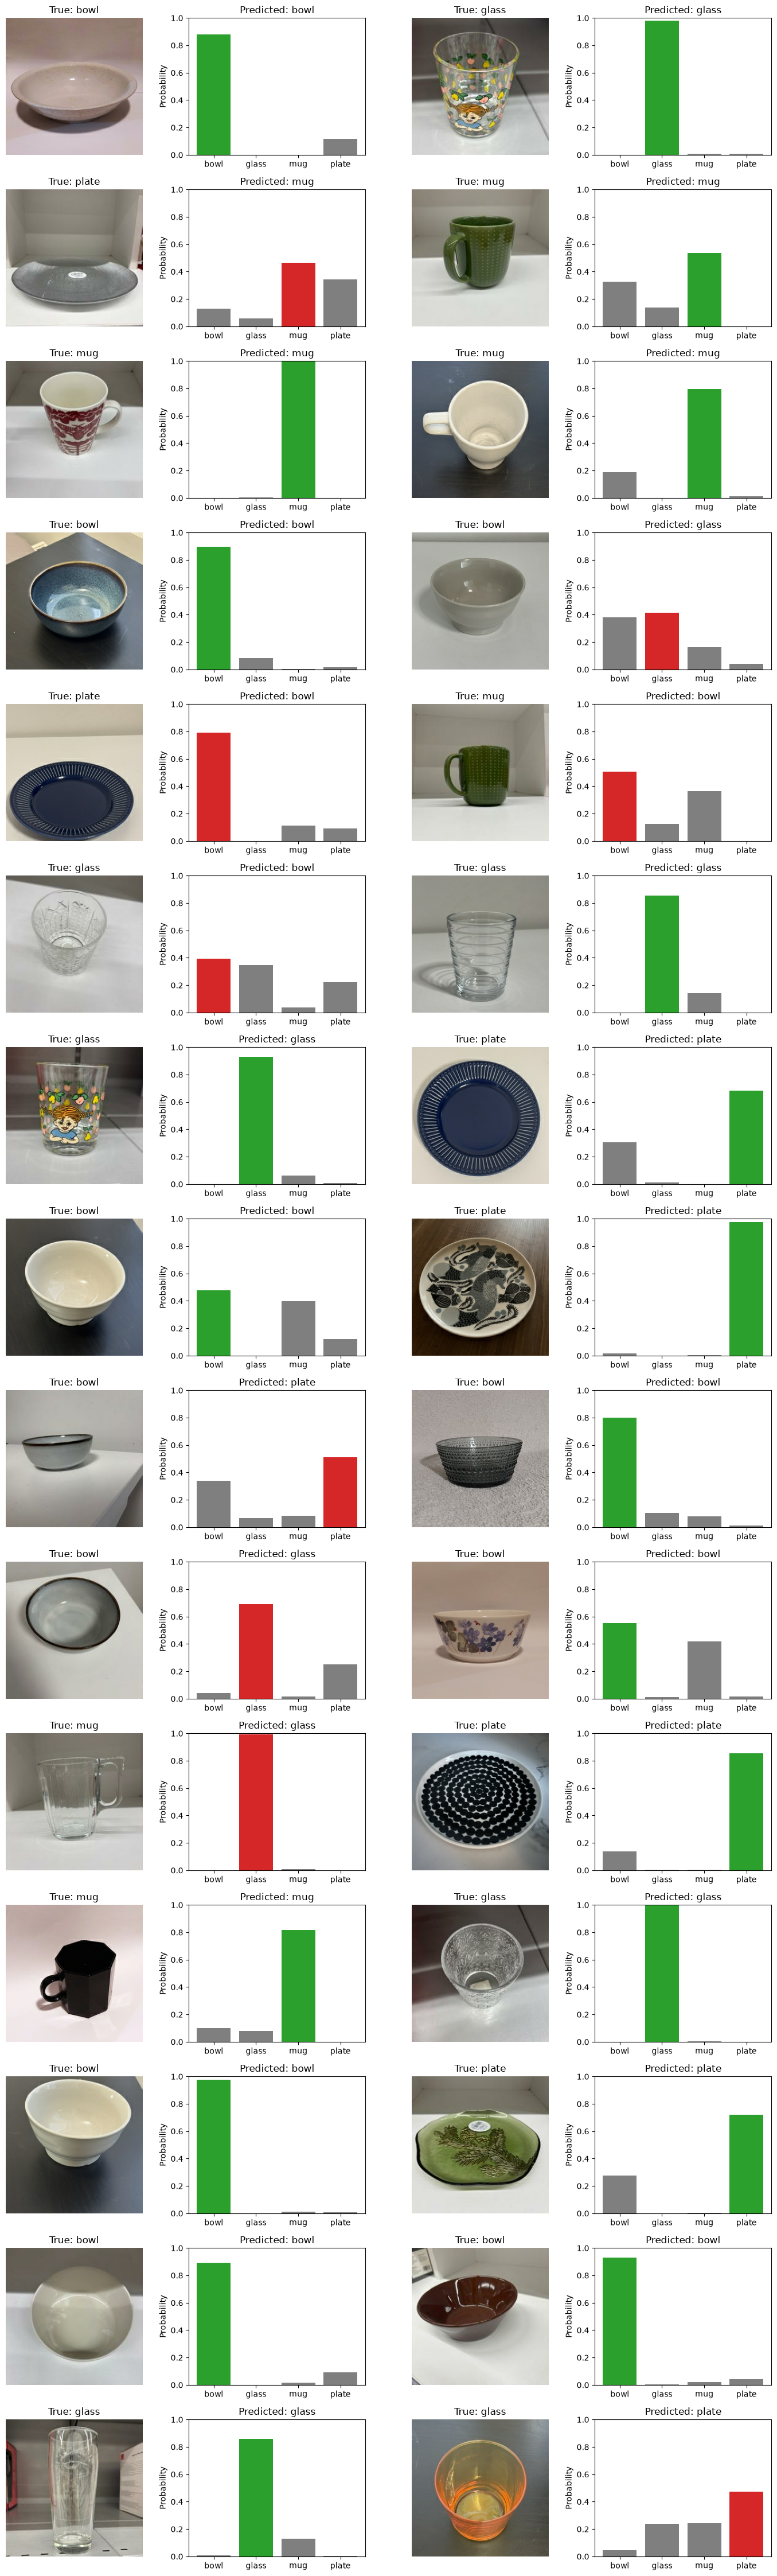

In [13]:
start = 0
images_n = 30
rows = images_n // 2

x, y = next(iter(test_dataset.unbatch().shuffle(1000).batch(images_n)))
probs = test_model.predict(x)

plt.figure(figsize=(14, 3 * rows))

for k in range(images_n):
    i = start + k
    true_label = int(y[i])
    pred_label = int(np.argmax(probs[i]))
    correct = true_label == pred_label

    plt.subplot(rows, 4, 2 * k + 1)
    plt.imshow(x[i].numpy().astype("uint8"))
    plt.axis("off")
    plt.title(f"True: {class_names[true_label]}")

    plt.subplot(rows, 4, 2 * k + 2)
    colors = ["tab:gray"] * len(class_names)
    colors[pred_label] = "tab:green" if correct else "tab:red"
    plt.bar(class_names, probs[i], color=colors)
    plt.ylim(0, 1)
    plt.ylabel("Probability")
    plt.title(f"Predicted: {class_names[pred_label]}")

plt.tight_layout()
plt.show()

|Test|Modification|Test accuracy (%)|Test loss|Training time (s)|Conclusion|
|---|---|---|---|---|---|
|Original model|-|55.8|1.102|52.2|Baseline. The model starts to overfit around epoch 4.|
|Version 1|Adds Dropout(0.1)|53.7|1.267|41.3|Slightly worse than the original. Test accuracy is lower, test loss is higher and overfitting is more visible in the learning curves.|
|Version 2|Adds data augmentation: 0.2 for RandomRotation, RandomZoom, RandomContrast|46.3|1.231|63.6|Augmentation at 0.2 is likely too strong for this dataset.|
|Version 3|Modifies data augmentation from 0.2 to 0.1|58.9|1.074|55.5|Better than Version 2. Lower augmentation delays overfitting until it starts around epoch 7.|
|Version 4|Adds Conv2D(16) and MaxPooling2D|64.2|1.284|51.9|Higher test accuracy but test loss also increased. A gap between the training and validation curves appears around epoch 8, but it stays constant until around epoch 20, when it starts to grow and the model begins to overfit.|
|Version 5|Modifies Conv2D(16) to Conv2D(32)|67.4|0.869|68.7|Better on both test accuracy and test loss. Same observation for learning curves as in Version 4. Overfitting starts around epoch 21.|
|Version 6|Modifies parameters for a few Conv2D layers|68.4|0.959|58.6|Test accuracy is about the same as Version 5, test loss is slightly higher and training is faster. The training and validation curves follow each other more closely until overfitting starts around epoch 20.|
|Version 7|Adds BatchNormalization layer before first Conv2D layer.|74.7|0.733|222.6|More accurate and less loss. Plotting shows overfitting.|
|Version 8|Adds learning_rate=0.0001 to optimizer, and batch_size=128 to model fit|74.7|0.633|305.2|Same accuracy but less loss than on Version 7. Overfitting starts around epoch 50. The overall overfitting trend lessens, observed from plotting. Training time has increased as more epochs are run.|
|Version 9|Increases dropout to 0.3|72.6|0.610|409.4|Around same performance as in Version 8. Plotting is cleaner, the training and validation curves follow each other more closely.|

Training times are affected by computer performance. If computer has been under heavy load before a model is run and is running hot, it is likely that the model will train for longer vs when a computer is cooler.

**Original model**

```python
model = keras.Sequential([
    keras.Input(shape=(224, 224, 3)),
    layers.Rescaling(1.0/255),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(128, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   

    layers.Conv2D(256, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   
    
    layers.Flatten(),
    layers.Dense(len(class_names), activation="softmax"),
])
```

**Version 1**<br>
**Added layers: Dropout(0.1)**

```python
model = keras.Sequential([
    keras.Input(shape=(224, 224, 3)),
    layers.Rescaling(1.0/255),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(128, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   

    layers.Conv2D(256, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   
    
    layers.Flatten(),
    layers.Dropout(0.1),
    layers.Dense(len(class_names), activation="softmax"),
])
```

**Version 2**<br>
**Added layers: data_augmentation(0.2), Dropout(0.1)**

```python
model = keras.Sequential([
    keras.Input(shape=(224, 224, 3)),
    data_augmentation,
    layers.Rescaling(1.0/255),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(128, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   

    layers.Conv2D(256, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   
    
    layers.Flatten(),
    layers.Dropout(0.1),
    layers.Dense(len(class_names), activation="softmax"),
])
```

**Version 3**<br>
**Added layers: data_augmentation(0.1), Dropout(0.1)**

```python
model = keras.Sequential([
    keras.Input(shape=(224, 224, 3)),
    data_augmentation,
    layers.Rescaling(1.0/255),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(128, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   

    layers.Conv2D(256, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   
    
    layers.Flatten(),
    layers.Dropout(0.1),
    layers.Dense(len(class_names), activation="softmax"),
])
```

**Version 4**<br>
**Added layers: data_augmentation(0.1), Conv2D(16) and MaxPooling2D, Dropout(0.1)**

```python
model = keras.Sequential([
    keras.Input(shape=(224, 224, 3)),
    data_augmentation,
    layers.Rescaling(1.0/255),

    layers.Conv2D(16, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(128, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   

    layers.Conv2D(256, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   
    
    layers.Flatten(),
    layers.Dropout(0.1),
    layers.Dense(len(class_names), activation="softmax"),
])
```

**Version 5**<br>
**Added layers: data_augmentation(0.1), change Conv2D(16) to Conv2D(32), Dropout(0.1)**

```python
model = keras.Sequential([
    keras.Input(shape=(224, 224, 3)),
    data_augmentation,
    layers.Rescaling(1.0/255),

    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(128, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   

    layers.Conv2D(256, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   
    
    layers.Flatten(),
    layers.Dropout(0.1),
    layers.Dense(len(class_names), activation="softmax"),
])
```

**Version 6**<br>
**Added layers: data_augmentation(0.1), changed values for Conv2D() layers, Dropout(0.1)**

```python
model = keras.Sequential([
    keras.Input(shape=(224, 224, 3)),
    data_augmentation,
    layers.Rescaling(1.0/255),

    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   

    layers.Conv2D(128, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   
    
    layers.Flatten(),
    layers.Dropout(0.1),
    layers.Dense(len(class_names), activation="softmax"),
])
```

**Version 7**<br>
**Added layers: BatchNormalization, data_augmentation(0.1), changed values for Conv2D() layers, Dropout(0.1)**

```python
model = keras.Sequential([
    keras.Input(shape=(224, 224, 3)),
    data_augmentation,
    layers.Rescaling(1.0/255),

    layers.BatchNormalization(),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   

    layers.Conv2D(128, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   
    
    layers.Flatten(),
    layers.Dropout(0.1),
    layers.Dense(len(class_names), activation="softmax"),
])
```

**Version 8**<br>
**Added layers: BatchNormalization, data_augmentation(0.1), changed values for Conv2D() layers, Dropout(0.1)**<br>
**Added learning_rate=0.0001 to optimizer**
**Added batch_size=128 to model fit**

```python
model = keras.Sequential([
    keras.Input(shape=(224, 224, 3)),
    data_augmentation,
    layers.Rescaling(1.0/255),

    layers.BatchNormalization(),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   

    layers.Conv2D(128, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   
    
    layers.Flatten(),
    layers.Dropout(0.1),
    layers.Dense(len(class_names), activation="softmax"),
])
```

**Version 9**<br>
**Added layers: BatchNormalization, data_augmentation(0.1), changed values for Conv2D() layers, Dropout(0.3)**<br>
**Added learning_rate=0.0001 to optimizer**
**Added batch_size=128 to model fit**

```python
model = keras.Sequential([
    keras.Input(shape=(224, 224, 3)),
    data_augmentation,
    layers.Rescaling(1.0/255),

    layers.BatchNormalization(),
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    
    layers.Conv2D(64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   

    layers.Conv2D(128, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),   
    
    layers.Flatten(),
    layers.Dropout(0.3),
    layers.Dense(len(class_names), activation="softmax"),
])
```

In [14]:
## Kirjoitetaan uuden notebookiin

## Dataset description Riikka

## Mallien suorituskyvyn vertailun: Nur

## Kohtaamasi haasteet ja ratkaisut Anni
- Kuvien ottaaminen, taustan päättääminen, esim: värikas tai musta-valkoinen, asento
- Kuvien esikäsittely: rajaus, koon muuttaminen.
- Kuvien laittaminen repoon
- Datan jakaminen: eri hakemistoihin harjoitus-, validointi- ja testidatalle,
- Datan jaon vaikeus: manuaalinen ja automaattinen skriptilla.
- Ylioppimiseen vähentäminen, hyvää tarkkuus, ja loss
- Finetuned mallin ajaamiseen hiitaus: piti miettiä huolellaa mitä muokkaa, ennen kuin ajaa malli.

## Pohdinnan eri mallien soveltuvuudesta ongelmaan Sandra
- CNN malli ei soveltuu koviin hyvin, kun meillä on vähän dataa.
- Feature_Extraction_VGG16 malli antaa parrempia tuloksia, on paljon nopeampi verrattuna CNN malli, mutta tulos ei ollut 100% prosenttin tarkkudella, loss... 
- Fine_tuned malli on erittäin hidas verrattuna muu 2 malli...

## Teköälyn käyttö Anni
- kuvien esitkäsittely skripti
- kuvien alustava jakoon ennen kuin manuaalisesti jaoteltu
- Debuggaus
- Plottaukseen